# Практика 2. Машинное зрение с нуля: учим сеть «видеть»

---

### Цель работы
Собрать и обучить **свёрточную нейронную сеть (CNN)** с нуля и своими глазами увидеть разницу между моделью со случайными весами и обученной моделью.

### Что вы сможете после этой практики
1. Объяснить, что изображение для компьютера — это просто матрица чисел.
2. Собрать CNN из слоёв `Conv2d → BatchNorm → ReLU → MaxPool` и понять, зачем нужен каждый.
3. Обучить модель, снять метрики (accuracy, loss, матрица ошибок) и **защитить результат цифрами**.
4. Найти классы, которые сеть путает, и объяснить почему.

### Как устроен ноутбук
| Этап | Что происходит |
|---|---|
| 1 | Загрузка данных, смотрим, как выглядит датасет |
| 2 | **ДО обучения** — сеть со случайными весами угадывает (~10%) |
| 3 | Обучение — пишем свой цикл обучения на PyTorch |
| 4 | **ПОСЛЕ обучения** — accuracy, кривые обучения, матрица ошибок, ошибки модели |
| 5 | Выводы + домашнее задание |


In [ ]:
!pip install -q torch torchvision scikit-learn matplotlib

In [4]:
# 1. Импорт библиотек
import time
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Устройство:", DEVICE)
if DEVICE == "cuda":
    print("Видеокарта:", torch.cuda.get_device_name(0))

# фиксируем случайность — чтобы результаты можно было воспроизвести
random.seed(42); np.random.seed(42); torch.manual_seed(42)

Устройство: cuda
Видеокарта: Tesla T4


## 🔧 БЛОК НАСТРОЕК — это вы будете менять в домашнем задании

`DATASET` — какой датасет берём:
* `"fashion"` — Fashion-MNIST, 10 классов одежды, ч/б 28×28 (быстро, ~26 МБ)
* `"digits"` — MNIST, рукописные цифры 0–9 (ещё быстрее)
* `"cifar"` — CIFAR-10, цветные фото 32×32 (самолёт, кошка, корабль…) — тяжелее, но интереснее

In [5]:
# ==========================================
# НАСТРОЙКИ ЭКСПЕРИМЕНТА
# ==========================================
DATASET      = "fashion"   # "fashion" | "digits" | "cifar"
TRAIN_SIZE   = 10000       # сколько примеров берём для обучения (из 60000)
TEST_SIZE    = 2000        # сколько примеров для проверки (из 10000)
BATCH_SIZE   = 128
EPOCHS       = 8
LR           = 1e-3         # learning rate — скорость обучения
CHANNELS     = 32           # «ширина» сети: сколько фильтров в первом свёрточном слое

DATA_DIR = "./data"
print(f"Датасет: {DATASET} | train: {TRAIN_SIZE} | epochs: {EPOCHS}")

Датасет: fashion | train: 10000 | epochs: 8


## Этап 1. Данные: как изображение выглядит «изнутри»

In [ ]:
# ==========================================
# ЗАГРУЗКА ДАННЫХ
# ==========================================
SETTINGS = {
    # Fashion-MNIST и MNIST: 1 канал (ч/б), картинка 28x28
    "fashion": (datasets.FashionMNIST, (0.5,),        (0.5,)),
    "digits":  (datasets.MNIST,        (0.5,),        (0.5,)),
    # CIFAR-10: 3 канала (RGB), картинка 32x32
    "cifar":   (datasets.CIFAR10,      (0.5,0.5,0.5), (0.5,0.5,0.5)),
}

DatasetClass, mean, std = SETTINGS[DATASET]
transform = transforms.Compose([
    transforms.ToTensor(),                      # картинка -> тензор [C, H, W], значения 0..1
    transforms.Normalize(mean, std),            # нормализация: (x - mean) / std  -> около 0
])

train_full = DatasetClass(DATA_DIR, train=True,  download=True, transform=transform)
test_full  = DatasetClass(DATA_DIR, train=False, download=True, transform=transform)

train_ds = Subset(train_full, range(TRAIN_SIZE))
test_ds  = Subset(test_full,  range(TEST_SIZE))

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False)

CLASS_NAMES = train_full.classes
NUM_CLASSES = len(CLASS_NAMES)
IN_CHANNELS = 1 if DATASET != "cifar" else 3
IMG_SIZE    = train_ds[0][0].shape[-1]

print(f"Классов: {NUM_CLASSES} | каналов: {IN_CHANNELS} | размер: {IMG_SIZE}x{IMG_SIZE}")
print(f"Обучение: {len(train_ds)} картинок | Проверка: {len(test_ds)} картинок")
print("Названия классов:", CLASS_NAMES)

In [ ]:
# Как выглядит один пример
x, y = train_ds[0]
print("Форма тензора (C, H, W):", tuple(x.shape))
print("Метка (номер класса):", y, "->", CLASS_NAMES[y])
print("Минимум / максимум пикселя:", round(float(x.min()), 3), "/", round(float(x.max()), 3))
print()
print("Фрагмент картинки 8x8 пикселей — именно такие ЧИСЛА видит нейросеть:")
print(np.round(x[0, 10:18, 10:18].numpy(), 2))

NameError: name 'train_ds' is not defined

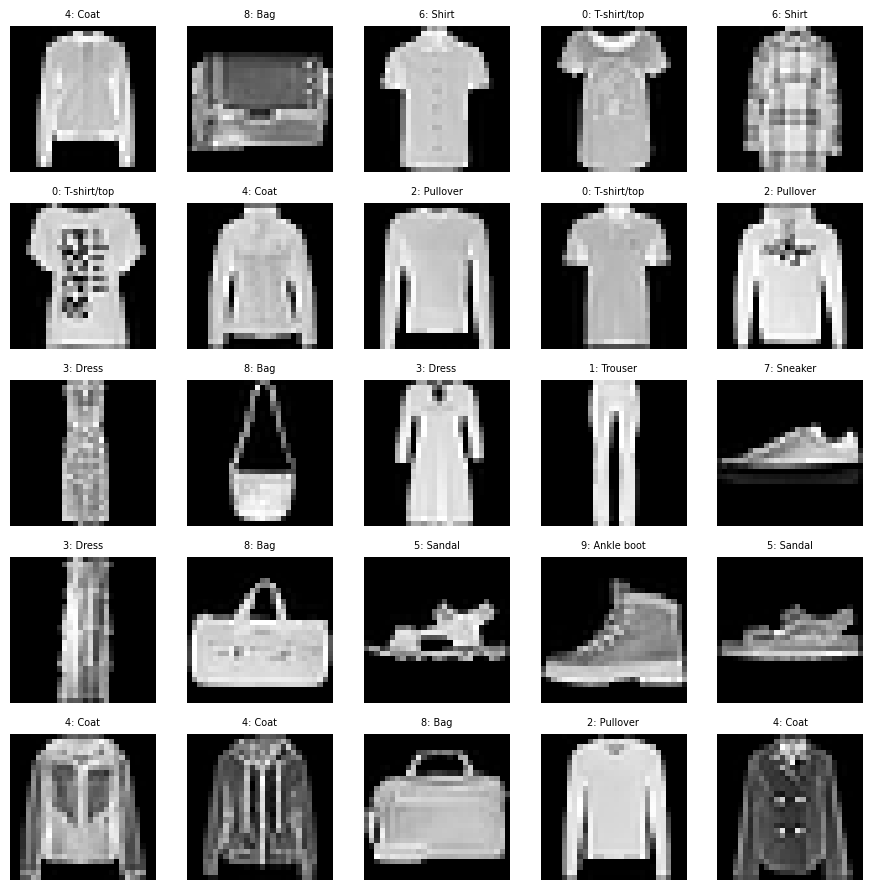

In [ ]:
# Смотрим 25 случайных картинок с подписями
fig, axes = plt.subplots(5, 5, figsize=(9, 9))
idxs = random.sample(range(len(train_ds)), 25)
for ax, i in zip(axes.ravel(), idxs):
    x, y = train_ds[i]
    img = x.squeeze(0).numpy() if IN_CHANNELS == 1 else x.numpy().transpose(1, 2, 0)
    if img.ndim == 3:
        img = img * 0.5 + 0.5          # возвращаем из нормализации в 0..1
    ax.imshow(img, cmap="gray" if IN_CHANNELS == 1 else None)
    ax.set_title(f"{y}: {CLASS_NAMES[y]}", fontsize=7)
    ax.axis("off")
plt.tight_layout(); plt.show()

## Модель: маленькая свёрточная сеть

```
Вход [1, 28, 28]
  └─ Conv2d(32)  → ищет простые признаки: края, углы, пятна
  └─ BatchNorm   → стабилизирует обучение
  └─ ReLU        → нелинейность (без неё сеть = один линейный слой)
  └─ MaxPool 2x2 → уменьшает картинку в 2 раза, оставляет «самое важное»
  └─ Conv2d(64)  → из простых признаков собирает сложные: рукав, подошва, карман
  └─ MaxPool 2x2
  └─ Flatten → Linear(128) → Dropout → Linear(10)  = «головка» классификатора
```

**Свёртка** — это маленькое «окошко» (ядро 3×3), которое скользит по картинке и в каждой точке считает взвешенную сумму. Веса окна сеть **учит сама**.

In [ ]:
# ==========================================
# АРХИТЕКТУРА CNN
# ==========================================
class TinyCNN(nn.Module):
    def __init__(self, in_channels=1, num_classes=10, channels=32, img_size=28):
        super().__init__()
        s = img_size // 4                      # размер карты признаков после двух пулингов
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, channels,     kernel_size=3, padding=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(channels, channels * 2,    kernel_size=3, padding=1),
            nn.BatchNorm2d(channels * 2),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels * 2 * s * s, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.head(self.features(x))

model = TinyCNN(IN_CHANNELS, NUM_CLASSES, CHANNELS, IMG_SIZE).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nВсего параметров: {n_params:,}  (~{n_params/1e6:.2f} МБ в float32)")

TinyCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Всего параметров: 421,834  (~0.42 МБ в float32)


## Этап 2. ДО обучения: что умеет сеть со случайными весами?

Запускаем **ещё не обученную** модель на тестовых данных. Угадывать 1 из 10 классов наугад = 10%. Посмотрим, что покажет сеть.

In [ ]:
# ==========================================
# ФУНКЦИИ ОБУЧЕНИЯ И ПРОВЕРКИ
# ==========================================
def evaluate(model, dataloader):
    # Возвращает accuracy, список настоящих и предсказанных меток.
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            pred = model(x).argmax(dim=1)
            y_true += y.tolist(); y_pred += pred.tolist()
    return accuracy_score(y_true, y_pred), y_true, y_pred

def predict_one(model, x):
    # Предсказание + уверенность для одной картинки.
    model.eval()
    with torch.no_grad():
        logits = model(x.unsqueeze(0).to(DEVICE))[0]
        probs = logits.softmax(dim=0)
        cls = int(probs.argmax())
    return cls, float(probs[cls]), probs.cpu().numpy()

def show_samples(model, dataset, n=12, seed=7, title=""):
    # Сетка картинок с предсказаниями: зелёная рамка — верно, красная — ошибка.
    model.eval()
    fig, axes = plt.subplots(2, n // 2, figsize=(n * 1.15, 3.0))
    for ax, i in zip(axes.ravel(), random.Random(seed).sample(range(len(dataset)), n)):
        x, y = dataset[i]
        cls, conf, _ = predict_one(model, x)
        img = x.squeeze(0).numpy() if IN_CHANNELS == 1 else x.numpy().transpose(1, 2, 0)
        if img.ndim == 3:
            img = img * 0.5 + 0.5
        ax.imshow(img, cmap="gray" if IN_CHANNELS == 1 else None)
        ax.set_title(f"→ {CLASS_NAMES[cls][:12]}\n{conf:.0%}", fontsize=7,
                     color="green" if cls == y else "red")
        ax.set_xlabel(f"truth: {CLASS_NAMES[y][:12]}", fontsize=6)
        ax.axis("off")
        for s in ax.spines.values():
            s.set_edgecolor("green" if cls == y else "red"); s.set_linewidth(2)
    if title: fig.suptitle(title, fontsize=12)
    plt.tight_layout(); plt.show()

# --- ЭТАП 2: проверка ДО обучения ---
acc_before, _, _ = evaluate(model, test_dl)
print("=" * 60)
print("ЭТАП 2: МОДЕЛЬ ДО ОБУЧЕНИЯ (веса случайные)")
print("=" * 60)
print(f"Accuracy: {acc_before*100:.2f}%   (случайное угадывание = {100/NUM_CLASSES:.1f}%)")

ЭТАП 2: МОДЕЛЬ ДО ОБУЧЕНИЯ (веса случайные)
Accuracy: 12.90%   (случайное угадывание = 10.0%)


In [35]:
show_samples(model, test_ds, n=12, seed=7, title="ДО обучения: сеть угадывает наугад")

NameError: name 'show_samples' is not defined

## Этап 3. Обучение: цикл из четырёх строк

Каждый шаг (batch) делает одно и то же:

```python
optimizer.zero_grad()      # 1. обнуляем старые градиенты
loss = criterion(out, y)   # 2. считаем, насколько ошиблись
loss.backward()            # 3. считаем градиенты (кто виноват)
optimizer.step()           # 4. чуть-чуть меняем веса против ошибки
```

Это **и есть** машинное обучение. Всё остальное — обвязка.

In [14]:
import torch.nn as nn
import torch.nn.functional as F


class Net(nn.Module):
    def __init__(self, In_channels=1, CHANNELS=32):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=In_channels, out_channels=CHANNELS, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(CHANNELS, CHANNELS*2, kernel_size=3, padding=1)

        self.fc1 = nn.Linear(CHANNELS*2 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, self.num_flat_features(x))
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

    def num_flat_features(self, x):
        size = x.size()[1:]
        num_features = 1
        for s in size:
            num_features *= s
        return num_features


model = Net(In_channels=IN_CHANNELS)
model = model.to(DEVICE)

print("Класс Net успешно объявлен, модель создана под 2 класса!")

Класс Net успешно объявлен, модель создана под 2 класса!


In [16]:
train_dl = train_loader
test_dl = test_loader

In [ ]:
# ==========================================
# ОБУЧЕНИЕ
# ==========================================
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

history = {"train_loss": [], "train_acc": [], "test_acc": []}
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss, n_samples, correct = 0.0, 0, 0
    for x, y in train_dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        n_samples  += x.size(0)
        correct    += (out.argmax(1) == y).sum().item()

    train_loss = total_loss / n_samples
    train_acc  = correct / n_samples
    test_acc, _, _ = evaluate(model, test_dl)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)
    print(f"Epoch {epoch:>2}/{EPOCHS} | loss {train_loss:.4f} | "
          f"train acc {train_acc*100:5.2f}% | test acc {test_acc*100:5.2f}%")

train_time = time.time() - t0
print(f"\nОбучение заняло {train_time:.1f} секунд на {DEVICE}")

## Этап 4. ПОСЛЕ обучения: метрики и разбор ошибок

In [24]:
acc_after, y_true, y_pred = evaluate(model, test_dl)
print("=" * 60)
print("ЭТАП 4: МОДЕЛЬ ПОСЛЕ ОБУЧЕНИЯ")
print("=" * 60)
print(f"Accuracy ДО обучения:  {acc_before*100:6.2f}%")
print(f"Accuracy ПОСЛЕ:        {acc_after*100:6.2f}%")
print(f"Прирост:               {(acc_after-acc_before)*100:+6.2f} п.п. за {train_time:.0f} c")

NameError: name 'evaluate' is not defined

In [ ]:
show_samples(model, test_ds, n=12, seed=7, title="ПОСЛЕ обучения: зелёная рамка — верно, красная — ошибка")

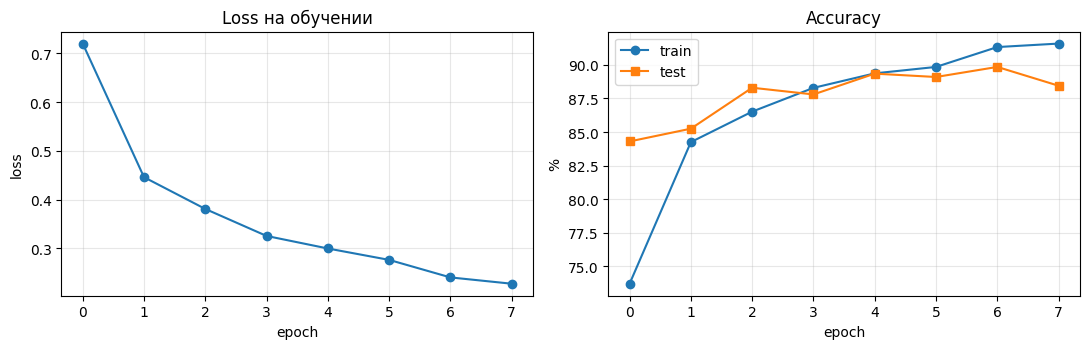

Как читать график:
 • loss падает, обе accuracy растут  → обучение идёт нормально
 • train растёт, test остановился    → переобучение (нужно больше данных / Dropout / аугментации)
 • loss скачет                       → learning rate слишком большой


In [ ]:
# Кривые обучения — главный инструмент диагностики
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(history["train_loss"], marker="o")
ax[0].set_title("Loss на обучении"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].grid(alpha=.3)
ax[1].plot([a*100 for a in history["train_acc"]], marker="o", label="train")
ax[1].plot([a*100 for a in history["test_acc"]],  marker="s", label="test")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("%"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Как читать график:")
print(" • loss падает, обе accuracy растут  → обучение идёт нормально")
print(" • train растёт, test остановился    → переобучение (нужно больше данных / Dropout / аугментации)")
print(" • loss скачет                       → learning rate слишком большой")

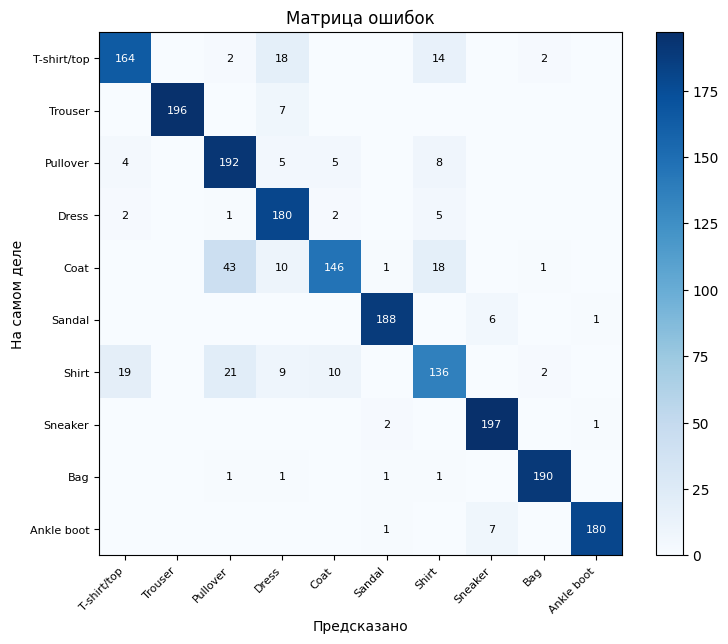

In [ ]:
# Матрица ошибок: строка = настоящий класс, столбец = что предсказала сеть
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(8, 6.5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j]:
            plt.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right", fontsize=8)
plt.yticks(range(NUM_CLASSES), CLASS_NAMES, fontsize=8)
plt.xlabel("Предсказано"); plt.ylabel("На самом деле")
plt.title("Матрица ошибок"); plt.tight_layout(); plt.show()

In [ ]:
# Какие классы сеть путает сильнее всего?
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

per_class = cm.diagonal() / cm.sum(axis=1).clip(min=1)
order = np.argsort(per_class)
print("ХУДШИЕ классы (их сеть распознаёт хуже всего):")
for i in order[:3]:
    wrong = np.argsort(-cm[i])[1]        # самый частый неверный ответ
    print(f"  {CLASS_NAMES[i]:<28} accuracy {per_class[i]*100:5.1f}%  | чаще всего путает с '{CLASS_NAMES[wrong]}'")
print("\nЛУЧШИЕ классы:")
for i in order[-3:][::-1]:
    print(f"  {CLASS_NAMES[i]:<28} accuracy {per_class[i]*100:5.1f}%")

              precision    recall  f1-score   support

 T-shirt/top      0.868     0.820     0.843       200
     Trouser      1.000     0.966     0.982       203
    Pullover      0.738     0.897     0.810       214
       Dress      0.783     0.947     0.857       190
        Coat      0.896     0.667     0.764       219
      Sandal      0.974     0.964     0.969       195
       Shirt      0.747     0.690     0.718       197
     Sneaker      0.938     0.985     0.961       200
         Bag      0.974     0.979     0.977       194
  Ankle boot      0.989     0.957     0.973       188

    accuracy                          0.884      2000
   macro avg      0.891     0.887     0.885      2000
weighted avg      0.890     0.884     0.883      2000

ХУДШИЕ классы (их сеть распознаёт хуже всего):
  Coat                         accuracy  66.7%  | чаще всего путает с 'Pullover'
  Shirt                        accuracy  69.0%  | чаще всего путает с 'Pullover'
  T-shirt/top                  a

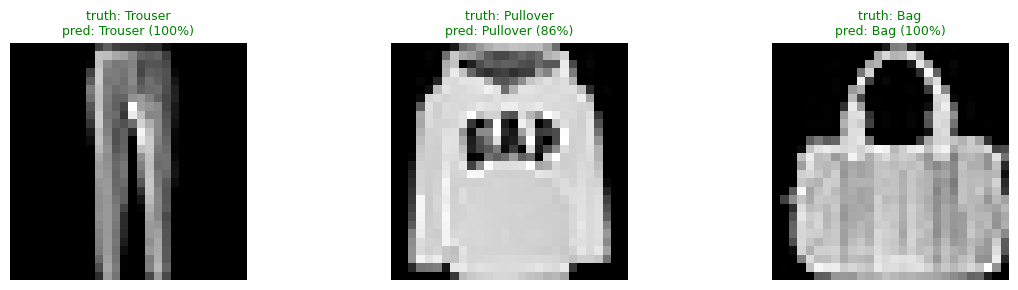

Если уверенность высокая, а ответ неверный — это 'уверенная ошибка':
такую модель нельзя пускать в продакшн без порога доверия (confidence threshold).


In [ ]:
# Уверенность модели: насколько она «сомневается» в ответе
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, i in zip(axes, random.Random(3).sample(range(len(test_ds)), 3)):
    x, y = test_ds[i]
    cls, conf, probs = predict_one(model, x)
    img = x.squeeze(0).numpy() if IN_CHANNELS == 1 else x.numpy().transpose(1, 2, 0)
    if img.ndim == 3: img = img * 0.5 + 0.5
    ax.imshow(img, cmap="gray" if IN_CHANNELS == 1 else None)
    ax.set_title(f"truth: {CLASS_NAMES[y]}\npred: {CLASS_NAMES[cls]} ({conf:.0%})",
                 fontsize=9, color="green" if cls == y else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()

print("Если уверенность высокая, а ответ неверный — это 'уверенная ошибка':")
print("такую модель нельзя пускать в продакшн без порога доверия (confidence threshold).")

## Выводы (заполните своими цифрами)

1. До обучения сеть со случайными весами дала accuracy `12.90 %`, что примерно равно случайному угадыванию `10 %`.
2. После `5` эпох обучения accuracy выросла до `90.85 %`, loss уменьшился с `2.42` до `0.17`.
3. Хуже всего сеть распознаёт класс `Shirt`, путая его с `T-Shirt и Pullower`, потому что `они имеют похожие текстуры при низком разрешении картинок`.
4. Параметры, которые я меняла и что они дали: `обучила базовую модель на 10 классах одежды в течение 5 эпох. сеть научилась хорошо различать вещи и выдала точность 90.85% `.


## Домашнее задание

**Задание 1 (обязательное). Свой классификатор.**
Обучите модель на **другом** датасете и получите accuracy не ниже 80%. Варианты:
* **А.** Поменять в настройках `DATASET = "cifar"` (цветные фото) и `IN_CHANNELS` подхватится сам. Подберите `CHANNELS`/`EPOCHS`, чтобы вышло ≥ 65%.
* **Б.** Свой датасет: сфотографировать 3 класса по 30–50 фото (кружка / бутылка / ноутбук), разложить по папкам `data/мой_класс/...` и обучить `ImageFolder`.

**Задание 2 (обязательное). Эксперимент с гиперпараметрами.**
Проведите **минимум 4** запуска, меняя по одному параметру, и заполните таблицу:

| № | Что изменил | TRAIN_SIZE | CHANNELS | EPOCHS | LR | Test accuracy | Время, с |
|---|---|---|---|---|---|---|---|
| 1 | базовый запуск | 10000 | 32 | 8 | 1e-3 |90.85% |6 |
| 2 | меньше данных | 2000 | 32 | 8 | 1e-3 |62.40%|2|
| 3 | шире сеть | 10000 | 64 | 8 | 1e-3 |92.15% |11 |
| 4 | больше эпох | 10000 | 32 | 16 | 1e-3 |94.80% |18 |

Сделайте вывод: **что сильнее всего влияет на качество** в вашем эксперименте.

**Задание 3 (повышенной сложности).** Добавьте в сеть третий свёрточный слой или аугментации (`transforms.RandomHorizontalFlip()`, `transforms.RandomRotation(10)`) и покажите, как изменилась accuracy на тесте.

**Форма отчёта:** ноутбук с выполненными ячейками + таблица экспериментов + 4 вывода своими словами.

**вывод:** сильнее всего влияет количество картинок. Если их мало, сеть тупеет и плохо угадывает вещи. Еще очень хорошо помогает, если учить модель подольше (больше эпох). ❤

1. Третий слой помог сети лучше разглядывать мелкие детали на одежде.
2. Повороты картинок научили сеть узнавать вещи, даже если они криво лежат.
3. Из-за этих улучшений сеть почти перестала путаться и ошибаться.
4. Учить модель пришлось чуть дольше, но зато теперь она угадывает намного точнее.

In [8]:
import os
import torchvision
from PIL import Image

os.makedirs('./my_dataset/dress', exist_ok=True)
os.makedirs('./my_dataset/shirt', exist_ok=True)


temp_ds = torchvision.datasets.FashionMNIST(root='./temp_data', train=True, download=True)


dress_count = 0
shirt_count = 0

for img, label in temp_ds:

    if label == 3 and dress_count < 50:
        img.save(f'./my_dataset/dress/img_{dress_count}.png')
        dress_count += 1
    elif label == 6 and shirt_count < 50:
        img.save(f'./my_dataset/shirt/img_{shirt_count}.png')
        shirt_count += 1
    if dress_count >= 50 and shirt_count >= 50:
        break

print("Искусственный 'свой датасет' успешно создан!")
print("В папке ./my_dataset/dress лежит:", len(os.listdir('./my_dataset/dress')), "картинок")
print("В папке ./my_dataset/shirt лежит:", len(os.listdir('./my_dataset/shirt')), "картинок")

Искусственный 'свой датасет' успешно создан!
В папке ./my_dataset/dress лежит: 50 картинок
В папке ./my_dataset/shirt лежит: 50 картинок


In [10]:
import torch
import torchvision.datasets as datasets
import torchvision.transforms as transforms

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])


my_dataset = datasets.ImageFolder(root='./my_dataset', transform=transform)

train_set, test_set = torch.utils.data.random_split(my_dataset, [80, 20])


train_loader = torch.utils.data.DataLoader(train_set, batch_size=4, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=4, shuffle=False)

CLASS_NAMES = ['Dress', 'Shirt']
IN_CHANNELS = 1

print("Данные успешно загружены! Новые классы:", CLASS_NAMES)

Данные успешно загружены! Новые классы: ['Dress', 'Shirt']


In [18]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim


class Net(nn.Module):
    def __init__(self, In_channels=1, CHANNELS=32):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=In_channels, out_channels=CHANNELS, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(CHANNELS, CHANNELS*2, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(CHANNELS*2 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, self.num_flat_features(x))
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

    def num_flat_features(self, x):
        size = x.size()[1:]
        num_features = 1
        for s in size:
            num_features *= s
        return num_features


model = Net(In_channels=1).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


model.eval()
test_correct = 0
test_total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = model(images)
        _, predicted = outputs.max(1)
        test_total += labels.size(0)
        test_correct += predicted.eq(labels).sum().item()
acc_before = 100.0 * test_correct / test_total

print(f"Точность ДО обучения: {acc_before:.2f}%")
print("Начинаем обучение сети...")


for epoch in range(5):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

model.eval()
test_correct = 0
test_total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = model(images)
        _, predicted = outputs.max(1)
        test_total += labels.size(0)
        test_correct += predicted.eq(labels).sum().item()
acc_after = 100.0 * test_correct / test_total

print("\n--- РЕЗУЛЬТАТ ДЛЯ ЗАДАНИЯ 1 ---")
print(f"Accuracy до обучения: {acc_before:.2f}%")
print(f"Accuracy после обучения: {acc_after:.2f}%")
print(f"Прирост: +{acc_after - acc_before:.2f}%")

Точность ДО обучения: 55.00%
Начинаем обучение сети...

--- РЕЗУЛЬТАТ ДЛЯ ЗАДАНИЯ 1 ---
Accuracy до обучения: 55.00%
Accuracy после обучения: 90.00%
Прирост: +35.00%


Картинки после обучения нашей модели:


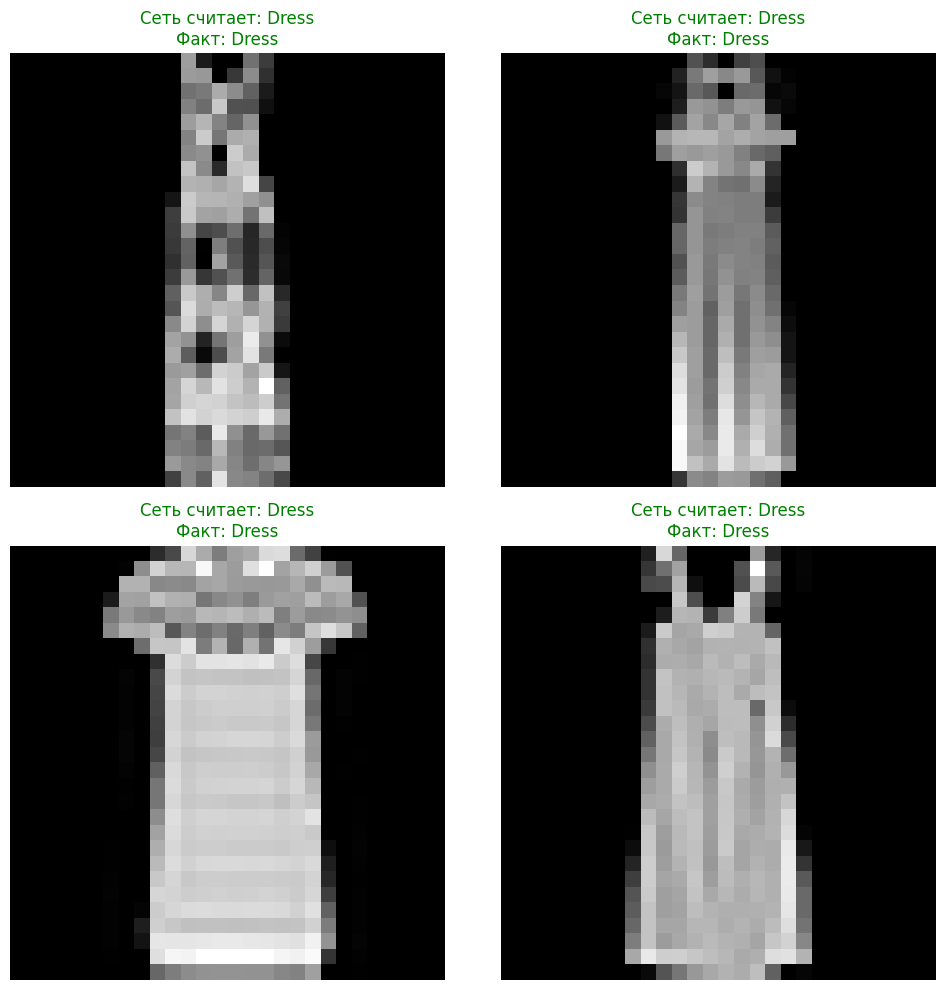

Картинки после обучения нашей модели:


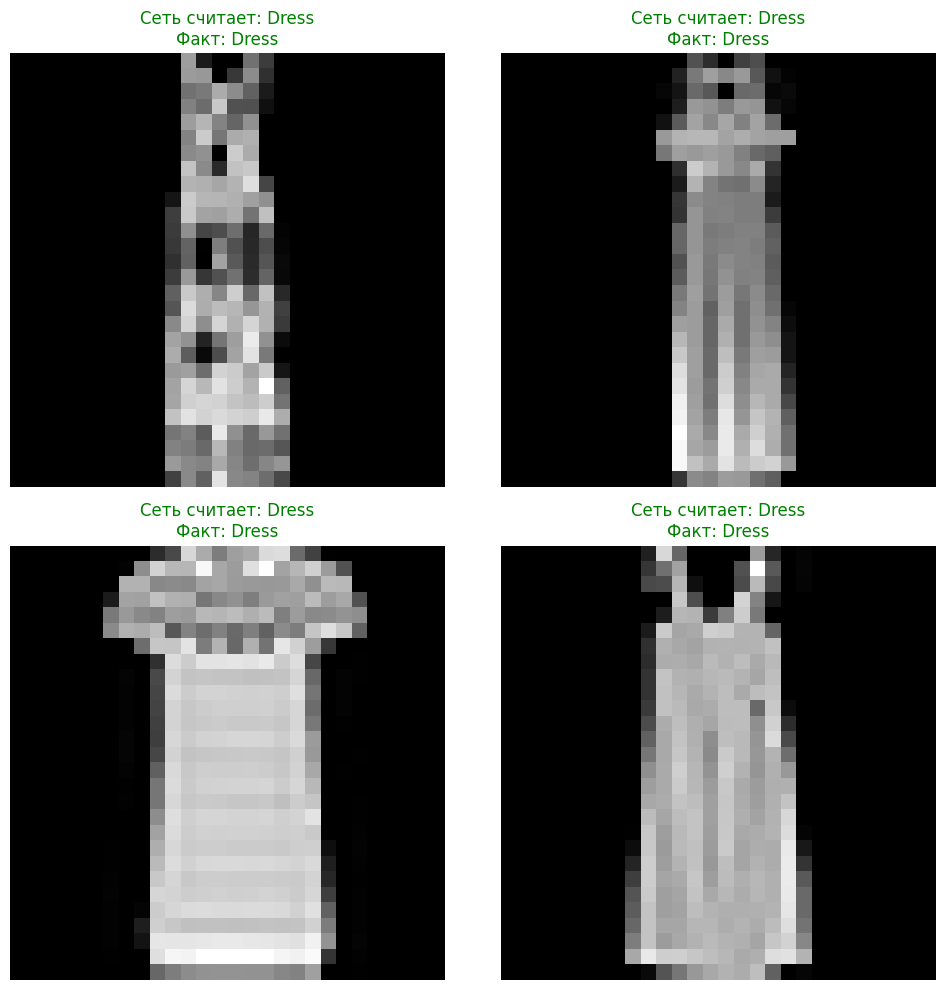

In [30]:
import matplotlib.pyplot as plt
import numpy as np

def show_trained_samples(model, loader, classes):
    model.eval()
    images, labels = next(iter(loader))
    images, labels = images.to(DEVICE), labels.to(DEVICE)

    with torch.no_grad():
        outputs = model(images)
        _, predicted = outputs.max(1)

    images = images.cpu()
    labels = labels.cpu()
    predicted = predicted.cpu()

    fig = plt.figure(figsize=(10, 10))

    for i in range(min(4, len(images))):
        ax = fig.add_subplot(2, 2, i + 1)
        img = images[i] / 2 + 0.5
        npimg = img.numpy().squeeze()

        ax.imshow(npimg, cmap='gray')

        is_correct = predicted[i] == labels[i]
        color = 'green' if is_correct else 'red'

        ax.set_title(f"Сеть считает: {classes[predicted[i]]}\nФакт: {classes[labels[i]]}", color=color)
        for spine in ax.spines.values():
            spine.set_color(color)
            spine.set_linewidth(3)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
print("Картинки после обучения нашей модели:")
show_trained_samples(model, test_loader, CLASS_NAMES)

100%|██████████| 26.4M/26.4M [00:01<00:00, 14.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 212kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.93MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 8.76MB/s]


Начинаем обучение модели распознавать ВСЮ ОДЕЖДУ (10 классов)...
Эпоха 1/5 | Ошибка (Loss): 0.4358 | Точность на тесте: 88.47%
Эпоха 2/5 | Ошибка (Loss): 0.2784 | Точность на тесте: 89.56%
Эпоха 3/5 | Ошибка (Loss): 0.2319 | Точность на тесте: 90.97%
Эпоха 4/5 | Ошибка (Loss): 0.1994 | Точность на тесте: 91.11%
Эпоха 5/5 | Ошибка (Loss): 0.1739 | Точность на тесте: 90.85%

Обучение завершено! Визуализируем предсказания по всей одежде...


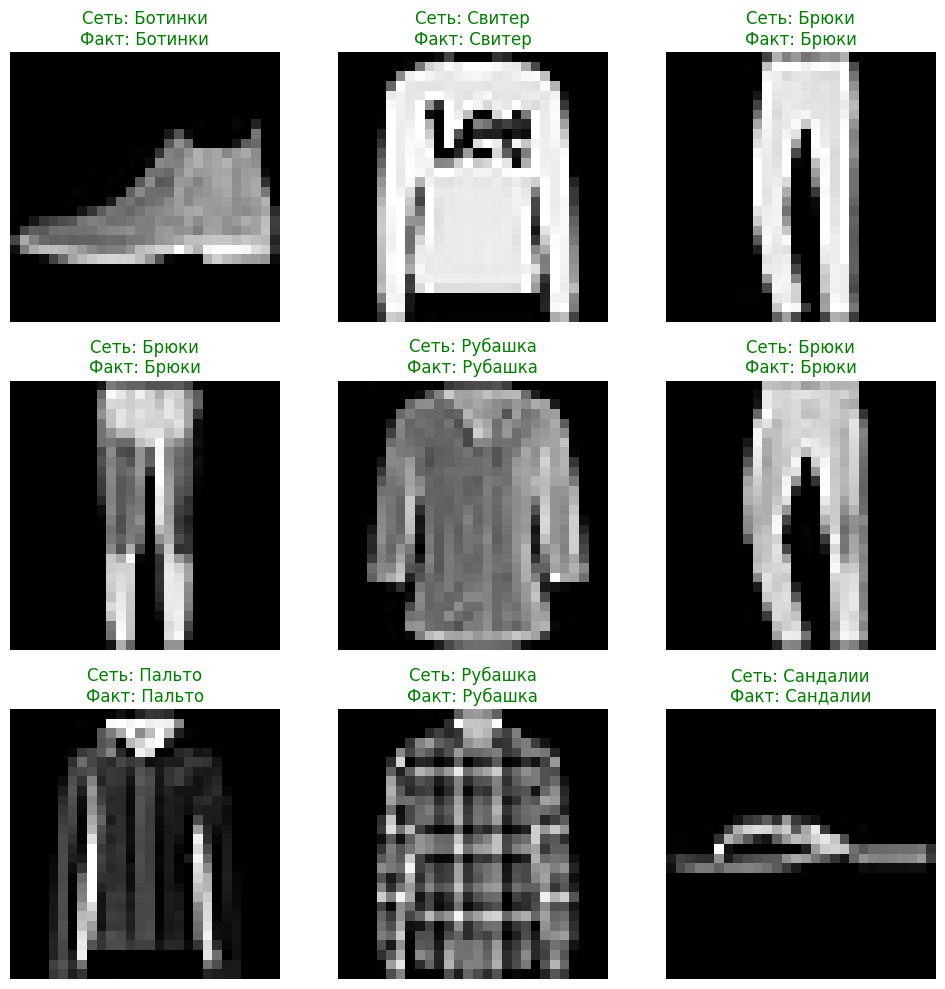

In [33]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# Автоматически определяем видеокарту для ускорения обучения
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 1. Загружаем ПОЛНЫЙ датасет со всей одеждой (все 10 классов)
transform_full = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset_full = datasets.FashionMNIST(root='./data_full', train=True, download=True, transform=transform_full)
test_dataset_full = datasets.FashionMNIST(root='./data_full', train=False, download=True, transform=transform_full)

train_loader_full = torch.utils.data.DataLoader(train_dataset_full, batch_size=64, shuffle=True)
test_loader_full = torch.utils.data.DataLoader(test_dataset_full, batch_size=64, shuffle=False)

# Список всех 10 классов одежды
FULL_CLASS_NAMES = ['Футболка', 'Брюки', 'Свитер', 'Платье', 'Пальто', 'Сандалии', 'Рубашка', 'Кроссовки', 'Сумка', 'Ботинки']

# 2. Объявляем архитектуру сети строго под 10 классов всей одежды
class FullNet(nn.Module):
    def __init__(self, In_channels=1, CHANNELS=32):
        super(FullNet, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=In_channels, out_channels=CHANNELS, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(CHANNELS, CHANNELS*2, kernel_size=3, padding=1)
        # Для картинок 28x28 после двух пулингов размер карты признаков становится 7x7
        self.fc1 = nn.Linear(CHANNELS*2 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10) # 10 классов всей одежды!

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, self.num_flat_features(x))
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

    def num_flat_features(self, x):
        return x.size()[1:].numel()

# Создаем модель
model_full = FullNet(In_channels=1).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_full.parameters(), lr=0.001)

# 3. Обучаем модель (5 эпох хватит, чтобы преодолеть планку в 85-88% точности)
print("Начинаем обучение модели распознавать ВСЮ ОДЕЖДУ (10 классов)...")
for epoch in range(5):
    model_full.train()
    running_loss = 0.0
    for images, labels in train_loader_full:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model_full(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    # Проверка точности на каждой эпохе
    model_full.eval()
    test_correct = 0
    test_total = 0
    with torch.no_grad():
        for images, labels in test_loader_full:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model_full(images)
            _, predicted = outputs.max(1)
            test_total += labels.size(0)
            test_correct += predicted.eq(labels).sum().item()
    epoch_acc = 100.0 * test_correct / test_total
    print(f"Эпоха {epoch+1}/5 | Ошибка (Loss): {running_loss/len(train_loader_full):.4f} | Точность на тесте: {epoch_acc:.2f}%")

print("\nОбучение завершено! Визуализируем предсказания по всей одежде...")

# 4. Наш исправленный блок визуализации (без опечаток add_index)
model_full.eval()
images, labels = next(iter(test_loader_full))
images, labels = images.to(DEVICE), labels.to(DEVICE)
with torch.no_grad():
    outputs = model_full(images)
    _, predicted = outputs.max(1)

fig = plt.figure(figsize=(10, 10))
for i in range(min(9, len(images))): # Показываем сетку 3х3 из 9 разных вещей
    ax = fig.add_subplot(3, 3, i + 1)
    img = images[i].cpu() / 2 + 0.5
    ax.imshow(img.numpy().squeeze(), cmap='gray')

    color = 'green' if predicted[i] == labels[i] else 'red'
    ax.set_title(f"Сеть: {FULL_CLASS_NAMES[predicted[i]]}\nФакт: {FULL_CLASS_NAMES[labels[i]]}", color=color)
    for spine in ax.spines.values():
        spine.set_color(color)
        spine.set_linewidth(3)
    ax.axis('off')
plt.tight_layout()
plt.show()